# Empirical-Bayes shrinkage for matchup win rates

Prototype and checks behind the website's numbers. The data comes from the raw match
files in `data/raw/matches/` (run `uv run python pipeline/sync_raw.py` first), counted by
the same code the site build uses (`pipeline/build.py`), so these tables match the live site.

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np

# notebook_data.py (next to this notebook) runs build.py's counting over every match
from notebook_data import load_tables
from shrinkage import K   # the prior strength the website uses (20)

tables = load_tables()
matchups = tables["matchups"]
baselines = tables["baselines"]

# raw win rate per cell (v1 stored these in Postgres; now we compute them)
matchups["winrate"] = matchups["wins"] / matchups["games"]
baselines["winrate"] = baselines["wins"] / baselines["games"]

print(f"{tables['match_count']} matches")
print(f"matchups: {len(matchups)} rows, baselines: {len(baselines)} rows")
matchups.head()

  read 3845 matches
3845 matches
matchups: 12916 rows, baselines: 642 rows


,champion,opponent,lane,games,wins,winrate
0,Teemo,Mordekaiser,TOP,15,6,0.400000
1,Trundle,Lillia,JUNGLE,3,0,0.000000
2,Yasuo,Kassadin,MIDDLE,10,7,0.700000
3,Syndra,Yunara,BOTTOM,6,2,0.333333
4,Sylas,Bard,UTILITY,2,1,0.500000


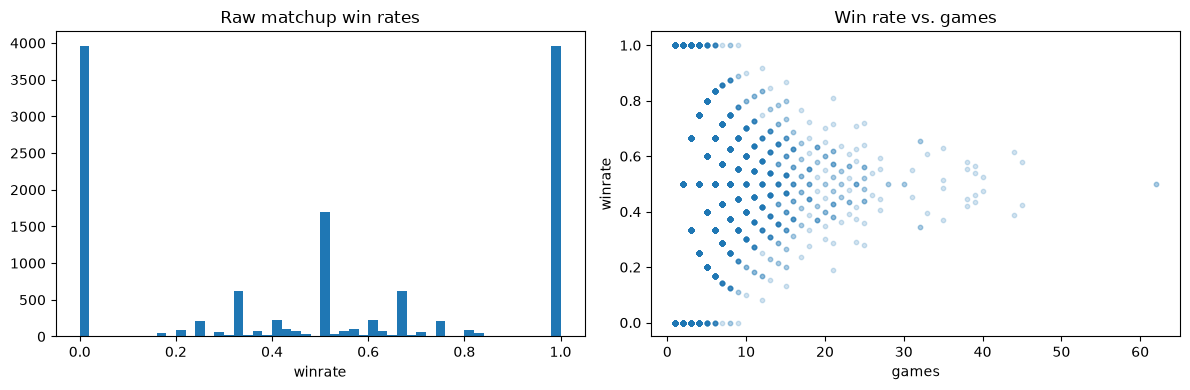

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# raw winrate distribution: note the spikes at 0.0, 0.5, 1.0
ax[0].hist(matchups["winrate"], bins=50)
ax[0].set_title("Raw matchup win rates")
ax[0].set_xlabel("winrate")

# winrate vs sample size: the funnel of doom
ax[1].scatter(matchups["games"], matchups["winrate"], alpha=0.2, s=10)
ax[1].set_title("Win rate vs. games")
ax[1].set_xlabel("games"); ax[1].set_ylabel("winrate")

plt.tight_layout(); plt.show()

## 2. Shrink each matchup toward its champion-lane baseline

In [3]:
from shrinkage import shrink

# baseline lookup: (champion, lane) -> that champion's lane win rate, shrunk toward 0.5.
# The baseline is a sample too: raw, a champion with 1 game in a lane gets 0% or 100%.
base = {}
for champ, lane, wins, games in zip(baselines["champion"], baselines["lane"],
                                    baselines["wins"], baselines["games"]):
    base[(champ, lane)] = shrink(wins, games, 0.5)

m = matchups.copy()
m["raw_winrate"] = m["wins"] / m["games"]

# each matchup's prior is its champion's lane baseline (0.5 if we have none)
priors = []
for champ, lane in zip(m["champion"], m["lane"]):
    priors.append(base.get((champ, lane), 0.5))
m["baseline"] = priors

k = K   # prior strength: the prior is "worth" 20 games. Section 3 fits it from the data.
m["alpha"] = k * m["baseline"]
m["beta"]  = k * (1 - m["baseline"])
m["shrunk_winrate"] = (m["wins"] + m["alpha"]) / (m["games"] + m["alpha"] + m["beta"])

m[["champion", "opponent", "lane", "games", "raw_winrate", "baseline", "shrunk_winrate"]].head(15)

,champion,opponent,lane,games,raw_winrate,baseline,shrunk_winrate
0,Teemo,Mordekaiser,TOP,15,0.400000,0.501931,0.458246
1,Trundle,Lillia,JUNGLE,3,0.000000,0.513889,0.446860
2,Yasuo,Kassadin,MIDDLE,10,0.700000,0.529801,0.586534
3,Syndra,Yunara,BOTTOM,6,0.333333,0.500000,0.461538
4,Sylas,Bard,UTILITY,2,0.500000,0.465517,0.468652
5,Mordekaiser,Teemo,TOP,15,0.600000,0.538462,0.564835
6,Lillia,Trundle,JUNGLE,3,1.000000,0.496774,0.562412
7,Kassadin,Yasuo,MIDDLE,10,0.300000,0.475806,0.417204
8,Yunara,Syndra,BOTTOM,6,0.666667,0.516981,0.551524
9,Bard,Sylas,UTILITY,2,0.500000,0.502618,0.502380


In [4]:
# the sparse cells: watch raw extremes get pulled to baseline
m[m["games"] <= 2].sort_values("games")[
    ["champion", "opponent", "lane", "games", "wins", "raw_winrate", "baseline", "shrunk_winrate"]
].head(15)

,champion,opponent,lane,games,wins,raw_winrate,baseline,shrunk_winrate
12912,DrMundo,Heimerdinger,TOP,1,1,1.0,0.502165,0.525871
12911,Lulu,Rell,UTILITY,1,1,1.0,0.500000,0.523810
12910,Cassiopeia,Kassadin,MIDDLE,1,1,1.0,0.514286,0.537415
12909,MasterYi,Taliyah,JUNGLE,1,1,1.0,0.492481,0.516649
12908,Rell,Lulu,UTILITY,1,0,0.0,0.486301,0.463144
121,Quinn,Volibear,TOP,1,1,1.0,0.515625,0.538690
116,Volibear,Quinn,TOP,1,0,0.0,0.462687,0.440654
115,Pantheon,Yuumi,UTILITY,1,1,1.0,0.511450,0.534715
37,Yone,Pantheon,MIDDLE,1,1,1.0,0.474619,0.499637
36,Shaco,Taliyah,JUNGLE,1,1,1.0,0.532110,0.554391


In [5]:
# the dense cells: shrinkage barely touches them
m[m["games"] >= 40].sort_values("games", ascending=False)[
    ["champion", "opponent", "lane", "games", "wins", "raw_winrate", "baseline", "shrunk_winrate"]
].head(10)

,champion,opponent,lane,games,wins,raw_winrate,baseline,shrunk_winrate
1273,Caitlyn,Ezreal,BOTTOM,62,31,0.500000,0.503748,0.500914
1269,Ezreal,Caitlyn,BOTTOM,62,31,0.500000,0.448037,0.487326
376,Caitlyn,Jhin,BOTTOM,45,26,0.577778,0.503748,0.554999
380,Jhin,Caitlyn,BOTTOM,45,19,0.422222,0.477444,0.439213
1168,Caitlyn,Ashe,BOTTOM,44,17,0.386364,0.503748,0.423046
1164,Ashe,Caitlyn,BOTTOM,44,27,0.613636,0.500000,0.578125
2361,MissFortune,Jhin,BOTTOM,40,19,0.475000,0.495671,0.481890
2366,Jhin,MissFortune,BOTTOM,40,21,0.525000,0.477444,0.509148


## 3. Fit the prior strength k from the data

First the quick estimate v1 used (method of moments on well-sampled matchups). It has a
flaw: it treats all the spread between win rates as real, but much of it is just binomial
noise from finite samples. More apparent spread means a smaller k, so it shrinks too little.

In [6]:
# NAIVE: fit the prior on well-sampled matchups only, using their raw spread.
# This ignores binomial noise, so k_hat comes out too small.
well = m[m["games"] >= 20]
rates = well["wins"] / well["games"]

mean = rates.mean()
var = rates.var()

# Method of moments for a Beta(alpha, beta):
# solve for the concentration k = alpha + beta from mean and variance.
k_hat = mean * (1 - mean) / var - 1

print(f"well-sampled matchups: {len(well)}")
print(f"mean winrate: {mean:.4f}   variance: {var:.5f}")
print(f"naive k_hat: {k_hat:.1f}")

well-sampled matchups: 116
mean winrate: 0.5000   variance: 0.01079
naive k_hat: 22.2


The fix is to fit k by **maximum marginal likelihood**, which is what `build.py` now does on
every run. If a cell's true win rate is drawn from Beta(k·prior, k·(1−prior)) and we then
see `wins` out of `games`, the chance of that result is (up to a constant)

$$
\frac{B(\mathrm{wins} + a,\ \mathrm{losses} + b)}{B(a, b)}, \qquad a = k \cdot \mathrm{prior},\ b = k \cdot (1 - \mathrm{prior})
$$

Multiplying that over every cell and picking the k that makes the data most likely accounts
for the binomial noise automatically, and uses every cell (no "20 games or more" cut-off).
`shrinkage.fit_k` tries each k on a grid and keeps the best. The grid tops out at 1000.

In [7]:
from shrinkage import K_GRID, fit_k, beta_binomial_log_likelihood


def print_curve(cells):
    """Log-likelihood of each k on the grid, relative to the best one (0 = best)."""
    scores = []
    for k in K_GRID:
        scores.append(beta_binomial_log_likelihood(cells, k))
    best = max(scores)
    for k, score in zip(K_GRID, scores):
        print(f"  k = {k:>5}: {score - best:8.1f}")


# level 1: every champion-lane win rate vs 0.5
lane_cells = []
for wins, games in zip(baselines["wins"], baselines["games"]):
    lane_cells.append((wins, games, 0.5))
k_lane = fit_k(lane_cells)
print("lane baselines vs 0.5:")
print_curve(lane_cells)

# level 2: every matchup vs its lane baseline, shrunk with the k just fitted
lane_prior = {}
for champ, lane, wins, games in zip(baselines["champion"], baselines["lane"],
                                    baselines["wins"], baselines["games"]):
    lane_prior[(champ, lane)] = shrink(wins, games, 0.5, k_lane)

matchup_cells = []
for champ, lane, wins, games in zip(m["champion"], m["lane"], m["wins"], m["games"]):
    matchup_cells.append((wins, games, lane_prior.get((champ, lane), 0.5)))
k_matchup = fit_k(matchup_cells)
print("matchups vs their lane baseline:")
print_curve(matchup_cells)

print(f"fitted: k_lane = {k_lane:g}, k_matchup = {k_matchup:g}   (naive estimate was {k_hat:.1f})")

lane baselines vs 0.5:
  k =     1:   -709.8
  k =     2:   -524.9
  k =     5:   -341.2
  k =    10:   -237.6
  k =    20:   -157.3
  k =    30:   -119.5
  k =    50:    -80.8
  k =    75:    -56.7
  k =   100:    -42.8
  k =   150:    -27.5
  k =   200:    -19.3
  k =   300:    -10.9
  k =   500:     -4.3
  k =   750:     -1.3
  k =  1000:      0.0
matchups vs their lane baseline:
  k =     1:  -2751.8
  k =     2:  -1465.4
  k =     5:   -537.7
  k =    10:   -220.5
  k =    20:    -80.5
  k =    30:    -42.5
  k =    50:    -18.1
  k =    75:     -8.9
  k =   100:     -5.3
  k =   150:     -2.5
  k =   200:     -1.4
  k =   300:     -0.6
  k =   500:     -0.2
  k =   750:     -0.1
  k =  1000:      0.0
fitted: k_lane = 1000, k_matchup = 1000   (naive estimate was 22.2)


In [8]:
# shrink every matchup the way the site now does, with the fitted values
priors = []
for champ, lane in zip(m["champion"], m["lane"]):
    priors.append(lane_prior.get((champ, lane), 0.5))
m["baseline"] = priors
m["shrunk_winrate"] = (m["wins"] + k_matchup * m["baseline"]) / (m["games"] + k_matchup)

print(f"shrunk matchup win rates now range from {m['shrunk_winrate'].min():.3f} "
      f"to {m['shrunk_winrate'].max():.3f}")
m.sort_values("games", ascending=False)[
    ["champion", "opponent", "lane", "games", "wins", "raw_winrate", "baseline", "shrunk_winrate"]
].head(10)

shrunk matchup win rates now range from 0.479 to 0.524


,champion,opponent,lane,games,wins,raw_winrate,baseline,shrunk_winrate
1269,Ezreal,Caitlyn,BOTTOM,62,31,0.500000,0.484076,0.485006
1273,Caitlyn,Ezreal,BOTTOM,62,31,0.500000,0.501518,0.501429
376,Caitlyn,Jhin,BOTTOM,45,26,0.577778,0.501518,0.504802
380,Jhin,Caitlyn,BOTTOM,45,19,0.422222,0.492063,0.489056
1168,Caitlyn,Ashe,BOTTOM,44,17,0.386364,0.501518,0.496665
1164,Ashe,Caitlyn,BOTTOM,44,27,0.613636,0.500000,0.504789
2361,MissFortune,Jhin,BOTTOM,40,19,0.475000,0.498613,0.497705
2366,Jhin,MissFortune,BOTTOM,40,21,0.525000,0.492063,0.493330
236,Jinx,Kaisa,BOTTOM,39,22,0.564103,0.501381,0.503736
232,Kaisa,Jinx,BOTTOM,39,17,0.435897,0.502439,0.499941


## 4. Backtest: does any of this predict games it hasn't seen?

Fit each estimator on 80% of the **matches**, then score its predicted win probability
on every lane in the other 20%. Splitting by match (not by rebuilt games, as v1 did)
means no game is ever both learned from and tested on.

Every estimator is compared to the dumbest possible one: always predict 50%. Two scores:

- **log loss** (lower is better). Always guessing 50% scores ln 2 = 0.6931. It punishes
  confident mistakes very hard, so a few predictions near 0% or 100% can dominate it.
- **Brier score**: the average squared error (lower is better). Always guessing 50% scores 0.25.

`vs_coin_flip` is the estimator's log loss minus the coin flip's (negative = better), with
a ±2 standard error band. The 10 rows from one match share a result, so they are not
independent: the standard error is computed from per-match totals.

In [9]:
from notebook_data import load_lane_games

# one row per player per game, paired with their lane opponent
lane_games = load_lane_games()
print(f"{len(lane_games)} rows from {lane_games['match_id'].nunique()} matches")
lane_games.head()

38438 rows from 3845 matches


,match_id,game_creation,champion,opponent,lane,win
0,NA1_5334237646,1753753298535,Teemo,Mordekaiser,TOP,0
1,NA1_5334237646,1753753298535,Trundle,Lillia,JUNGLE,0
2,NA1_5334237646,1753753298535,Yasuo,Kassadin,MIDDLE,0
3,NA1_5334237646,1753753298535,Syndra,Yunara,BOTTOM,0
4,NA1_5334237646,1753753298535,Sylas,Bard,UTILITY,0


The backtest code lives in `backtest.py` next to this notebook (the README figure uses it
too). In short:

- `random_match_split` shuffles the match ids and keeps 80% for training. `time_split`
  trains on the oldest 80% instead.
- `fit_counts` counts games and wins per champion-lane and per matchup, from training rows only.
- `predict` is one function for every estimator: a lane level (`lane_rate`, shrunk toward
  0.5 with `k_lane`) and a matchup level (`matchup_rate`, shrunk toward the lane level with
  `k_matchup`). A k of 0 means raw, `None` means skip that level, and `"fit"` means the k
  fitted on the training games with the same likelihood fit `build.py` uses.
- `backtest` scores every estimator in `ESTIMATORS` on the test rows.

In [10]:
from backtest import ESTIMATORS, random_match_split, time_split, backtest

for name, k_lane, k_matchup in ESTIMATORS:
    print(f"{name:40s} k_lane = {str(k_lane):5s} k_matchup = {k_matchup}")

train, test = random_match_split(lane_games)
print(f"\ntrain: {len(train)} rows, test: {len(test)} rows")
backtest(train, test)

constant 0.5                             k_lane = None  k_matchup = None
lane baseline, raw                       k_lane = 0     k_matchup = None
lane baseline, shrunk (K=20)             k_lane = 20.0  k_matchup = None
matchup, raw                             k_lane = None  k_matchup = 0
site before Nov 25: raw baseline, K=20   k_lane = 0     k_matchup = 20.0
site step 3a: shrunk baseline, K=20      k_lane = 20.0  k_matchup = 20.0
site now: fitted k                       k_lane = fit   k_matchup = fit

train: 30750 rows, test: 7688 rows
fitted on the training games: k_lane = 1000, k_matchup = 1000


,estimator,log_loss,brier,vs_coin_flip,plus_minus_2se
0,constant 0.5,0.6931,0.2500,0.0000,0.0000
1,"lane baseline, raw",0.7774,0.2548,0.0842,0.0304
2,"lane baseline, shrunk (K=20)",0.6956,0.2512,0.0025,0.0015
3,"matchup, raw",2.9387,0.3211,2.2455,0.2061
4,"site before Nov 25: raw baseline, K=20",0.7789,0.2556,0.0858,0.0305
5,"site step 3a: shrunk baseline, K=20",0.6973,0.2521,0.0042,0.0030
6,site now: fitted k,0.6931,0.2500,-0.0001,0.0003


In [11]:
# Same test, but split by TIME: train on the oldest 80% of matches, test on the newest 20%.
# This is how the site is really used (old games predict new ones). Caveat: most of the
# matches are from July 2026, so the newest 20% leans on late July plus a few months after.
old, new = time_split(lane_games)
backtest(old, new)

fitted on the training games: k_lane = 1000, k_matchup = 1000


,estimator,log_loss,brier,vs_coin_flip,plus_minus_2se
0,constant 0.5,0.6931,0.2500,0.0000,0.0000
1,"lane baseline, raw",0.7903,0.2555,0.0972,0.0306
2,"lane baseline, shrunk (K=20)",0.6969,0.2518,0.0037,0.0017
3,"matchup, raw",2.9118,0.3199,2.2186,0.2066
4,"site before Nov 25: raw baseline, K=20",0.7916,0.2561,0.0985,0.0306
5,"site step 3a: shrunk baseline, K=20",0.6983,0.2525,0.0051,0.0031
6,site now: fitted k,0.6933,0.2501,0.0002,0.0003


In [12]:
# Why was the old site's estimator (raw baselines) so much worse in log loss than in Brier?
# Look at how many of its predictions are extreme (5% or less, 95% or more).
from backtest import fit_counts, predict, log_loss_each

lane_counts, matchup_counts = fit_counts(train)
site_preds = []
for champ, opp, lane in zip(test["champion"], test["opponent"], test["lane"]):
    site_preds.append(predict(lane_counts, matchup_counts, champ, opp, lane, 0, K))
site_preds = np.array(site_preds)

y = test["win"].to_numpy()
extra_loss = log_loss_each(y, site_preds) - np.log(2)   # loss beyond a coin flip
extreme = (site_preds <= 0.05) | (site_preds >= 0.95)

print(f"extreme predictions: {extreme.sum()} of {len(site_preds)}")
print(f"share of the extra loss they cause: {extra_loss[extreme].sum() / extra_loss.sum():.0%}")
print(f"log loss of all the other predictions: {log_loss_each(y[~extreme], site_preds[~extreme]).mean():.4f}")

extreme predictions: 55 of 7688
share of the extra loss they cause: 92%
log loss of all the other predictions: 0.7004


### What this shows

- **Nothing beats always guessing 50%.** On both splits, no estimator has a `vs_coin_flip`
  meaningfully below zero. With about 3,800 matches, champion and matchup win rates don't
  predict held-out games any better than a coin flip.
- **The site before Nov 25 was clearly worse than a coin flip**, and almost all of that came
  from a handful of extreme predictions. The cause was the lane baselines: they were raw
  rates, so a champion with 1 game in a lane got a baseline of 0% or 100%, and every matchup
  for that champion in that lane was shrunk toward it (or used it outright when the matchup
  was never seen). Shrinking the baselines toward 0.5 (step 3a) removed most of the damage.
- **With k fitted from the training games (the site now), it ties the coin flip** (within
  ±0.0003). The fit lands on the cap of 1000 at both levels, which is the data saying it
  can't yet tell champions or matchups apart from 50%. As the daily crawl adds matches, the
  fitted k will come down by itself once real differences show up.
- **The v1 backtest's 3.68 vs 0.69** compared shrinkage against raw rates only. Shrinkage
  does beat raw rates by a lot, but that is a low bar.

So the honest claim is: shrinkage stops the site from reporting overconfident numbers off
tiny samples, and with k fitted from the data it never does worse than a coin flip. It is
not (yet) a forecast that beats one.

## 5. Personal layer: your games

In [13]:
# Your own games. build.py picks them out with MY_PUUID from your .env
# (v1 ran an Athena query here with the PUUID typed into the notebook).
personal = tables["personal"].sort_values("games", ascending=False).reset_index(drop=True)
personal["raw_winrate"] = personal["wins"] / personal["games"]

print(f"{len(personal)} distinct personal matchups, {personal['games'].sum()} total games")
personal.head(20)

329 distinct personal matchups, 740 total games


,champion,opponent,lane,games,wins,raw_winrate
0,Yasuo,Ahri,MIDDLE,19,14,0.736842
1,Yone,Akali,MIDDLE,14,4,0.285714
2,Yone,Ahri,MIDDLE,13,7,0.538462
3,Yasuo,Malzahar,MIDDLE,12,7,0.583333
4,Yone,Yasuo,MIDDLE,12,5,0.416667
5,Yasuo,Yone,MIDDLE,12,9,0.750000
6,Yone,Sylas,MIDDLE,11,4,0.363636
7,Yone,Viktor,MIDDLE,10,4,0.400000
8,Yasuo,Akali,MIDDLE,9,5,0.555556
9,Yasuo,Azir,MIDDLE,9,5,0.555556


In [14]:
# FIRST ATTEMPT, kept to show the mistake: shrink your record toward the RAW
# population matchup rate. Sparse population cells are noisy, so this chains
# noise onto noise. The next cell is the fix that build.py uses.

# Population matchup win rate = the prior for each personal cell
pop_lookup = matchups.set_index(["champion", "opponent", "lane"])["winrate"]

# champion-lane baseline = fallback prior when the population matchup cell is missing
base_lookup = baselines.set_index(["champion", "lane"])["winrate"]

def prior_for(row):
    # most-specific prior available: population matchup rate, else champion baseline, else 0.5
    p = pop_lookup.get((row["champion"], row["opponent"], row["lane"]))
    if p is not None:
        return p
    b = base_lookup.get((row["champion"], row["lane"]))
    return b if b is not None else 0.5

personal["population_winrate"] = personal.apply(prior_for, axis=1)

k = K
personal["shrunk_winrate"] = (
    (personal["wins"] + k * personal["population_winrate"]) /
    (personal["games"] + k)
)

# how much you beat (or trail) the baseline, honestly weighted by your sample size
personal["edge"] = personal["shrunk_winrate"] - personal["population_winrate"]

personal[[
    "champion", "opponent", "lane", "games", "wins",
    "raw_winrate", "population_winrate", "shrunk_winrate", "edge"
]].head(20)

,champion,opponent,lane,games,wins,raw_winrate,population_winrate,shrunk_winrate,edge
0,Yasuo,Ahri,MIDDLE,19,14,0.736842,0.656250,0.695513,0.039263
1,Yone,Akali,MIDDLE,14,4,0.285714,0.380952,0.341737,-0.039216
2,Yone,Ahri,MIDDLE,13,7,0.538462,0.500000,0.515152,0.015152
3,Yasuo,Malzahar,MIDDLE,12,7,0.583333,0.454545,0.502841,0.048295
4,Yone,Yasuo,MIDDLE,12,5,0.416667,0.447368,0.435855,-0.011513
5,Yasuo,Yone,MIDDLE,12,9,0.750000,0.552632,0.626645,0.074013
6,Yone,Sylas,MIDDLE,11,4,0.363636,0.565217,0.493689,-0.071529
7,Yone,Viktor,MIDDLE,10,4,0.400000,0.333333,0.355556,0.022222
8,Yasuo,Akali,MIDDLE,9,5,0.555556,0.476190,0.500821,0.024631
9,Yasuo,Azir,MIDDLE,9,5,0.555556,0.500000,0.517241,0.017241


In [15]:
# THE FIX: use the SHRUNK population matchup rate as the prior (hierarchical: priors shrink too).
# m holds the population matchups shrunk with the fitted k from section 3, as on the site;
# your own record is then shrunk toward that with the fixed K = 20.
pop_shrunk_lookup = m.set_index(["champion", "opponent", "lane"])["shrunk_winrate"]

def prior_for(row):
    p = pop_shrunk_lookup.get((row["champion"], row["opponent"], row["lane"]))
    if p is not None:
        return float(p)
    # fallback: the shrunk lane baseline from section 3
    return lane_prior.get((row["champion"], row["lane"]), 0.5)

personal["population_winrate"] = personal.apply(prior_for, axis=1)

k = K
personal["shrunk_winrate"] = (
    (personal["wins"] + k * personal["population_winrate"]) /
    (personal["games"] + k)
)
personal["edge"] = personal["shrunk_winrate"] - personal["population_winrate"]

personal[["champion","opponent","lane","games","wins",
          "raw_winrate","population_winrate","shrunk_winrate","edge"]].head(20)

,champion,opponent,lane,games,wins,raw_winrate,population_winrate,shrunk_winrate,edge
0,Yasuo,Ahri,MIDDLE,19,14,0.736842,0.515856,0.623516,0.107660
1,Yone,Akali,MIDDLE,14,4,0.285714,0.490423,0.406131,-0.084292
2,Yone,Ahri,MIDDLE,13,7,0.538462,0.492893,0.510844,0.017951
3,Yasuo,Malzahar,MIDDLE,12,7,0.583333,0.510141,0.537588,0.027447
4,Yone,Yasuo,MIDDLE,12,5,0.416667,0.491062,0.463164,-0.027898
5,Yasuo,Yone,MIDDLE,12,9,0.750000,0.512874,0.601797,0.088922
6,Yone,Sylas,MIDDLE,11,4,0.363636,0.494352,0.447969,-0.046383
7,Yone,Viktor,MIDDLE,10,4,0.400000,0.490366,0.460244,-0.030122
8,Yasuo,Akali,MIDDLE,9,5,0.555556,0.510640,0.524579,0.013939
9,Yasuo,Azir,MIDDLE,9,5,0.555556,0.511229,0.524985,0.013757


## 6. Items

In [16]:
# Yasuo's finished items, raw, across all his lanes.
# build.py only counts finished items (nothing builds out of them, 2000+ gold,
# purchasable), the same filter v1 applied here by hand.
items = tables["items"].copy()
items["raw_winrate"] = items["wins"] / items["games"]

yasuo_items = items[items["champion"] == "Yasuo"].sort_values("games", ascending=False)
yasuo_items[["item_name", "games", "wins", "raw_winrate"]].head(20)

,item_name,games,wins,raw_winrate
7,Immortal Shieldbow,504,277,0.549603
5,Blade of The Ruined King,449,230,0.512249
115,Infinity Edge,347,205,0.590778
433,Kraken Slayer,169,88,0.520710
114,Death's Dance,139,78,0.561151
416,Mortal Reminder,127,62,0.488189
8,Phantom Dancer,110,63,0.572727
992,Lord Dominik's Regards,94,55,0.585106
1764,Stridebreaker,62,37,0.596774
6,Wit's End,39,20,0.512821


In [17]:
# prior = the champion's overall win rate across all lanes
totals = baselines.groupby("champion")[["wins", "games"]].sum()
champ_overall = totals["wins"] / totals["games"]
items["prior"] = items["champion"].map(champ_overall).fillna(0.5)

k = K
items["shrunk_winrate"] = (items["wins"] + k * items["prior"]) / (items["games"] + k)
items["edge"] = items["shrunk_winrate"] - items["prior"]

# your champion, shrunk: watch the noisy tail collapse
items[items["champion"] == "Yasuo"].sort_values("games", ascending=False)[
    ["item_name","games","wins","raw_winrate","prior","shrunk_winrate","edge"]
].head(20)

,item_name,games,wins,raw_winrate,prior,shrunk_winrate,edge
7,Immortal Shieldbow,504,277,0.549603,0.517857,0.548391,0.030534
5,Blade of The Ruined King,449,230,0.512249,0.517857,0.512489,-0.005369
115,Infinity Edge,347,205,0.590778,0.517857,0.586804,0.068947
433,Kraken Slayer,169,88,0.520710,0.517857,0.520408,0.002551
114,Death's Dance,139,78,0.561151,0.517857,0.555705,0.037848
416,Mortal Reminder,127,62,0.488189,0.517857,0.492225,-0.025632
8,Phantom Dancer,110,63,0.572727,0.517857,0.564286,0.046429
992,Lord Dominik's Regards,94,55,0.585106,0.517857,0.573308,0.055451
1764,Stridebreaker,62,37,0.596774,0.517857,0.577526,0.059669
6,Wit's End,39,20,0.512821,0.517857,0.514528,-0.003329
